Análise de aprendizado de Idiomas no *Duolingo*
Objetivo do Notebook: analisar métricas de revisão, dificuldade e esquecimento dos usuários com base no dataset 

In [54]:
#imports
import pandas as pd 
import numpy as np  
import matplotlib.pyplot as plt 
import seaborn as sns

print ("BIBLIOTECAS CARREGADAS!")


BIBLIOTECAS CARREGADAS!


Nota sobre o volume de dados:

O dataset original completo contém cerca de 13 milhões de registros. Para otimizar a performance e permitir uma Análise Exploratória ágil e fluida, trabalharemos com uma amostra representativa de 200.000 linhas, volume robusto para identificar os padrões de aprendizado e comportamento dos usuários.

In [55]:
#Caminho dataset

caminho = "data/settles.acl16.learning_traces.13m.csv.gz"

df = pd.read_csv (caminho, nrows = 200_000)

print(f"Dimensões do DataFrame (linhas, colunas): {df.shape}")
display(df.head())

Dimensões do DataFrame (linhas, colunas): (200000, 12)


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


In [56]:
#Estudando o data frame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   p_recall           200000 non-null  float64
 1   timestamp          200000 non-null  int64  
 2   delta              200000 non-null  int64  
 3   user_id            200000 non-null  str    
 4   learning_language  200000 non-null  str    
 5   ui_language        200000 non-null  str    
 6   lexeme_id          200000 non-null  str    
 7   lexeme_string      200000 non-null  str    
 8   history_seen       200000 non-null  int64  
 9   history_correct    200000 non-null  int64  
 10  session_seen       200000 non-null  int64  
 11  session_correct    200000 non-null  int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 18.3 MB


In [57]:
#analisando estatísticas dos idiomas


analise_idiomas = df.groupby("learning_language").agg(
    total_licoes = ("p_recall", "count"),
    media_acerto = ("p_recall", "mean")
).sort_values(by="total_licoes", ascending=False)

display(analise_idiomas)


,total_licoes,media_acerto
learning_language,,
en,82336,0.898647
es,51183,0.893635
fr,29205,0.887250
de,21251,0.895194
it,10944,0.904537
pt,5081,0.907036


In [58]:
#verificando métricas em razão dos usuários
usuarios = df.groupby("user_id").agg(
    total_licoes=("p_recall", "count"),
    media_acerto = ("p_recall", "mean")
)

display(usuarios)

,total_licoes,media_acerto
user_id,,
u:-DF,114,0.909357
u:-TV,12,1.000000
u:-oe,17,0.877451
u:-wa,11,0.909091
u:0co,6,1.000000
...,...,...
u:zRd,7,0.757143
u:zdY,95,0.871930
u:zh7,7,1.000000


In [59]:
#verificando total de usuários únicos no dataset
total_usuarios_unicos = len(usuarios)
print(f"Total de usuários únicos: {total_usuarios_unicos}")

Total de usuários únicos: 5130


In [60]:
#visualizando os dados de métricas por usuários
print("\nEstatísticas de exercícios por usuário:")

display(usuarios["total_licoes"].describe())


Estatísticas de exercícios por usuário:


count    5130.000000
mean       38.986355
std        50.447850
min         1.000000
25%         7.000000
50%        23.000000
75%        48.000000
max       798.000000
Name: total_licoes, dtype: float64

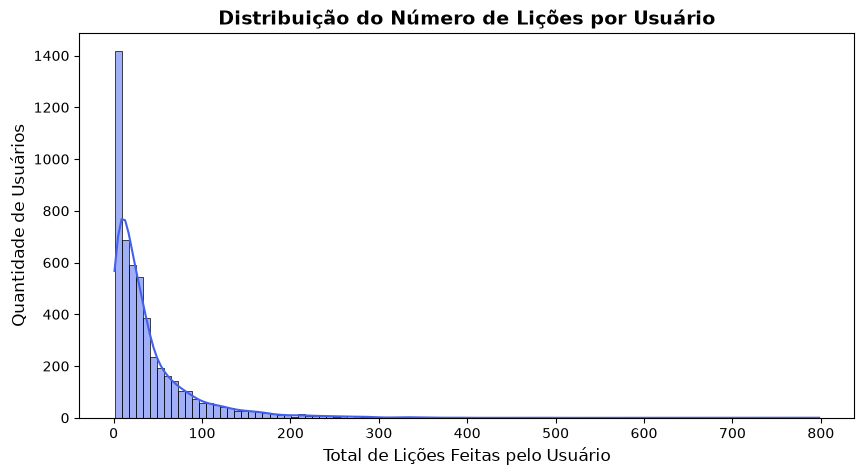

In [61]:
#construção de visualização gráfica
plt.figure(figsize=(10, 5))

#criando histograma
sns.histplot(data=usuarios, x="total_licoes", bins=100, kde=True, color="#4361ee")

#nomeando
plt.title("Distribuição do Número de Lições por Usuário", fontsize=14, weight="bold")
plt.xlabel("Total de Lições Feitas pelo Usuário", fontsize=12)
plt.ylabel("Quantidade de Usuários", fontsize=12)

plt.show()

A análise do gráfico nos permite observar alguns fatores interessantes:

Ao analisar até o ponto 100 do eixo das abscissas, observa-se que, conforme o número de lições aumenta, a quantidade de usuários diminui vertiginosamente. A partir disso, é possível inferir que se trata de usuários novos no app ou que ainda estão tentando vencer a inércia dos primeiros dias.

Ao atingir o limiar de 100 lições, a curva desacelera sua queda brusca e segue de forma mais estável (formando uma cauda longa). Esse grupo representa usuários retidos, que mantêm um alto *streak* (ofensiva de estudos) e são responsáveis por uma fatia desproporcional do volume total de aprendizado do app.


In [62]:
#Limpando as palavras do dataset
df["palavra_limpa"] = df["lexeme_string"].str.split("/").str[0]

#Agrupando as palavras pelo idioma

palavras = df.groupby(["palavra_limpa", "learning_language"]).agg(
    total_vezes=("p_recall", "count"),
    media_acerto=("p_recall", "mean")
).reset_index()

display(palavras)

,palavra_limpa,learning_language,total_vezes,media_acerto
0,',en,188,0.881894
1,'s,en,145,0.940616
2,<*sf>,de,295,0.904407
3,<*sf>,en,1311,0.915802
4,<*sf>,es,657,0.887874
...,...,...,...,...
5490,únicamente,es,5,0.600000
5491,útil,es,2,1.000000
5492,überall,de,1,1.000000
5493,übertragen,de,1,0.000000


In [63]:
#Controle de frequência para garantir precisão da análise
palavras_frequentes = palavras[palavras["total_vezes"] >= 60]
#display(palavras_frequentes)


#Analisando as 10 palavras mais fáceis e as 10 palavras mais difíceis segundo o dataset
analise_palavras = palavras_frequentes.sort_values(by="media_acerto", ascending=True).reset_index()

print("--------------------------")
print("PALAVRAS MAIS DIFÍCEIS")
print("--------------------------")

display(analise_palavras.head(10))



print("--------------------------")
print("PALAVRAS MAIS FÁCEIS")
print("--------------------------")

display(analise_palavras.tail(10))





--------------------------
PALAVRAS MAIS DIFÍCEIS
--------------------------


,index,palavra_limpa,learning_language,total_vezes,media_acerto
0,3465,on,en,160,0.748958
1,2892,madre,es,83,0.759036
2,1290,den,de,209,0.775974
3,4551,sobre,es,61,0.789071
4,4013,que,es,117,0.790598
5,4863,that,en,159,0.790681
6,5114,va,es,76,0.791667
7,4887,thursday,en,60,0.792361
8,3580,parents,en,84,0.793651
9,3377,nuestras,es,104,0.795650


--------------------------
PALAVRAS MAIS FÁCEIS
--------------------------


,index,palavra_limpa,learning_language,total_vezes,media_acerto
689,4862,thanks,en,150,0.971111
690,3563,pantalón,es,105,0.976190
691,844,chienne,fr,61,0.976230
692,768,carne,es,161,0.978261
693,3780,poisson,fr,62,0.979839
694,4617,speak,en,113,0.981037
695,3511,oui,fr,100,0.981333
696,3452,oil,en,249,0.983601
697,5354,willkommen,de,87,0.986590
698,1824,family,en,62,0.991935


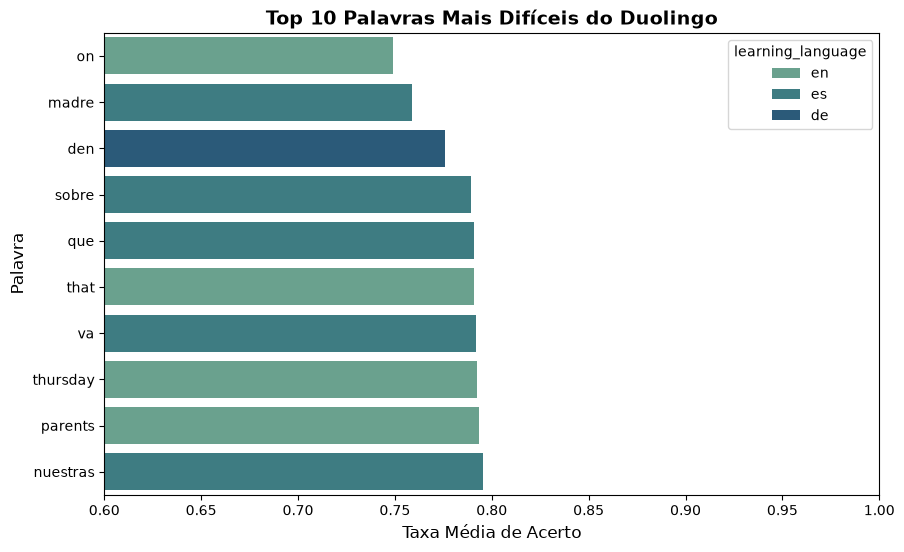

In [64]:
#Criando gráfico Seaborn para analisar as 10 palavras mais difíceis

top_10_dificeis = analise_palavras.head(10).reset_index()

#construção de visualização gráfica
plt.figure(figsize=(10, 6))

#criando gráfico
sns.barplot(
    data=top_10_dificeis,
    y="palavra_limpa",
    x="media_acerto",
    hue="learning_language",
    palette="crest"
)

#nomeando
plt.title("Top 10 Palavras Mais Difíceis do Duolingo", fontsize=14, weight="bold")
plt.xlabel("Taxa Média de Acerto", fontsize=12)
plt.ylabel("Palavra", fontsize=12)
plt.xlim(0.6, 1.0)

plt.show()

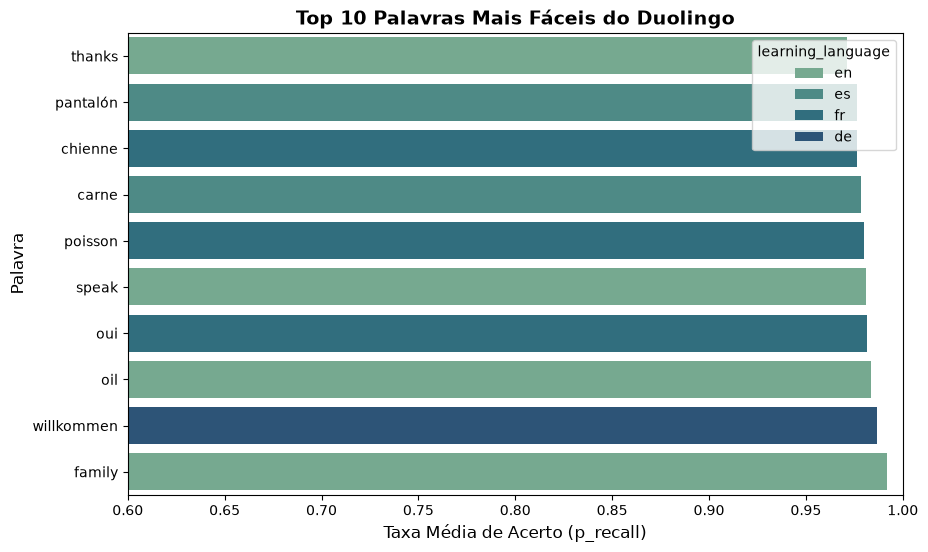

In [65]:
#Criando gráfico Seaborn para analisar as 10 palavras mais fáceis

top_10_fáceis = analise_palavras.tail(10).reset_index()

#construção de visualização gráfica
plt.figure(figsize=(10, 6))

#criando gráfico
sns.barplot(
    data=top_10_fáceis,
    y="palavra_limpa",
    x="media_acerto",
    hue="learning_language",
    palette="crest"
)

#nomeando
plt.title("Top 10 Palavras Mais Fáceis do Duolingo", fontsize=14, weight="bold")
plt.xlabel("Taxa Média de Acerto (p_recall)", fontsize=12)
plt.ylabel("Palavra", fontsize=12)
plt.xlim(0.6, 1.0)

plt.show()

Insight:

A partir dos gráficos que relacionam a dificuldade das palavras com base no "recall" dos usuários, podemos inferir algumas conclusões importantes.

As 10 palavras mais fáceis tratam-se puramente de substantivos. Isso significa que, independente do idioma estudado, as pessoas tendem a memorizar melhor palavras que são substantivos, pois elas são de fácil visualização mental e possuem um significado definido, sem grande dependência de flexão gramatical.

Diferentemente, ao analisar as 10 palavras mais difíceis, pode-se observar dentre elas a presença marcante de verbos e preposições. Por não se tratarem de coisas tangíveis, mas sim de conceitos relacionais e gramaticais abstratos, elas exigem maior esforço cognitivo, e novamente, esse padrão se repete independente do idioma.


In [ ]:
#ANALISE DE ESQUECIMENTO

#convertendo delta de segundos para dias
#1 hora = 60 minutos -> 60x60 = 3600 segundos em 1 hora -> 1 dia = 24 horas -> 24x3600 = 86400 -> 1 dia = 86400 segundos
df["dias_sem_revisão"] = df["delta"]/86400

#criando períodos
periodos = [-1, 1, 7, 14, 30, 90, 365, float("inf")]
periodos_definicao = ["Até 1 dia", "1 a 7 dias", "7 a 14 dias", "14 a 30 dias",
"1 a 3 meses", "3 meses a 1 ano", "mais de 1 ano"
]

df["faixa_tempo"] = pd.cut(df["dias_sem_revisão"], bins=periodos, labels=periodos_definicao)

#agrupando
retencao_tempo = df.groupby("faixa_tempo").agg(
    total_exercicios=("p_recall", "count"),
    taxa_acerto=("p_recall", "mean")
).reset_index()

display(retencao_tempo)

,faixa_tempo,total_exercicios,taxa_acerto
0,Até 1 dia,107813,0.906398
1,1 a 7 dias,55547,0.889463
2,7 a 14 dias,13830,0.881957
3,14 a 30 dias,11539,0.876849
4,1 a 3 meses,8269,0.869867
5,3 meses a 1 ano,2988,0.844991
6,mais de 1 ano,14,0.860119


<function matplotlib.pyplot.show(close=None, block=None)>

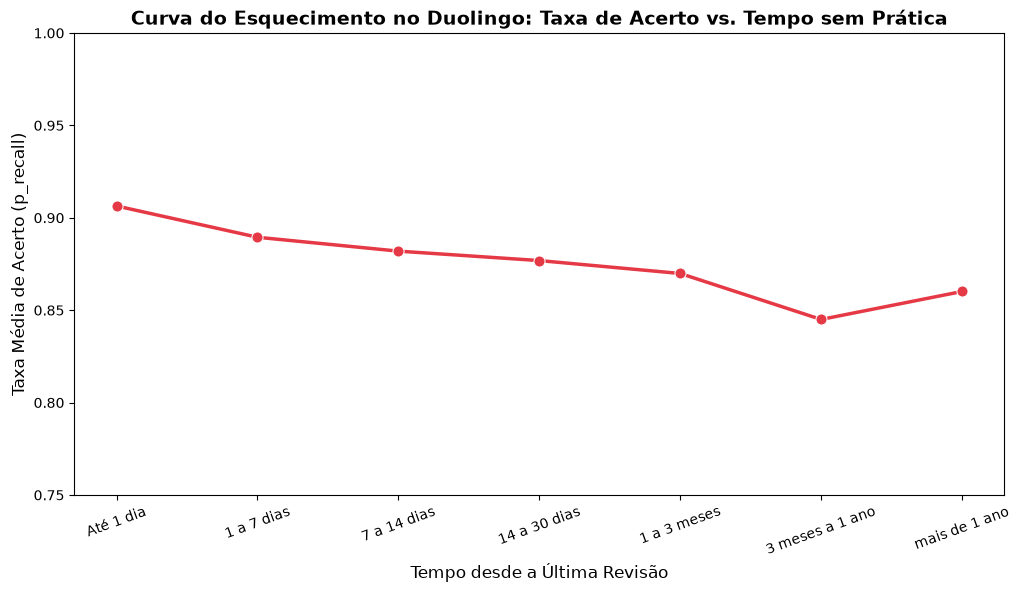

In [ ]:
#Criando gráfico para analisar a curva de esquecimento
plt.figure(figsize=(12, 6))

#criando gráfico
sns.lineplot(
    data=retencao_tempo,
    x="faixa_tempo",
    y="taxa_acerto",
    marker="o",
    color="#e63946",
    linewidth=2.5,
    markersize=8
)

#nomeando
plt.title("Curva do Esquecimento no Duolingo: Taxa de Acerto vs. Tempo sem Prática", fontsize=14, weight="bold")
plt.xlabel("Tempo desde a Última Revisão", fontsize=12)
plt.ylabel("Taxa Média de Acerto (p_recall)", fontsize=12)
plt.ylim(0.75, 1)
plt.xticks(rotation=20)

plt.show()

A partir da análise deste gráfico é perfeitamente possível observar a validação da curva de Ebbinghaus, quem revisa no mesmo dia atinge uma maior porcentagem de acerto, consequentemente maior retenção. Conforme o tempo desde a última revisão aumenta, a taxa cai progressivamente. 

Essa análise mostra a importância de aplicativos com algoritmo de SRS (Spaced repetition system), por meio desse mecanismo é possível fazer com que uma informação permaneça no cérebro por longos anos, ao contrário de quando o conteúdo é estudado apenas uma única vez, no qual parte da informação aprendida já é perdida nos primeiros dias se não houver revisão e a curva do gráfico cairá vertiginosamente.